# DIP super-resolution with a PnP improvement

This notebook compares the assignment baseline (Deep Image Prior) with a plug-and-play (PnP) refinement inspired by Lecture 9. The PnP stage alternates bicubic data-consistency updates with TV denoising and gradually decreases the denoiser strength. It never uses the HR reference during optimization; the reference is used only for evaluation.

**Run the cells from top to bottom on a Colab GPU runtime.**

In [1]:
# Colab setup. If you opened this notebook from GitHub, clone the repo first.
# In Colab: Runtime > Change runtime type > T4 GPU.
import os
import shutil
import subprocess
import sys
from pathlib import Path

os.chdir("/content")
ROOT = Path("/content/dip-sr")
REPO_URL = "https://github.com/Dhadheechi/dip-sr.git"
if ROOT.exists():
    shutil.rmtree(ROOT)
subprocess.check_call(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)])

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")
])
sys.path.insert(0, str(ROOT / "src"))
print(f"repo: {ROOT}")

repo: /content/dip-sr


## W&B setup

W&B is required for the assignment run tracking. Create a free account at [wandb.ai](https://wandb.ai), create or choose a project name, and run the next cell. Colab will show a login link; paste the API key when prompted. Do not put the key in the notebook.

In [2]:
import wandb

WANDB_PROJECT = "dip-sr-pnp"
USE_WANDB = True
if USE_WANDB:
    wandb.login()
print(f"W&B project: {WANDB_PROJECT}")

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: rdhadheechi (dhadheechi) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B project: dip-sr-pnp


In [11]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

from dip_sr import (
    ExperimentConfig,
    PnPConfig,
    make_image_pair,
    psnr,
    run_experiment,
    run_pnp_refinement,
    tensor_to_image,
)

SEED = 42
SCALE = 4
image_paths = [
    ROOT / "data" / "sr" / "zebra_GT.png",
    ROOT / "data" / "restoration" / "barbara.png",
    ROOT / "data" / "restoration" / "kate.png",
    ROOT / "data" / "denoising" / "F16_GT.png",
    ROOT / "data" / "feature_inversion" / "building.jpg",
    ROOT / "data" / "feature_inversion" / "monkey.jpg",
]

print("\n".join(str(path) for path in image_paths))
image = np.asarray(Image.open(image_path).convert("RGB"))
pair = make_image_pair(image, scale=SCALE)
print(f"device: {'cuda' if torch.cuda.is_available() else 'cpu'}")
print(f"HR: {tuple(pair.hr.shape[-2:])}, LR: {tuple(pair.lr.shape[-2:])}")

/content/dip-sr/data/sr/zebra_GT.png
/content/dip-sr/data/restoration/barbara.png
/content/dip-sr/data/restoration/kate.png
/content/dip-sr/data/denoising/F16_GT.png
/content/dip-sr/data/feature_inversion/building.jpg
/content/dip-sr/data/feature_inversion/monkey.jpg
device: cuda
HR: (388, 584), LR: (97, 146)


## 1. Baseline DIP

This is the unchanged baseline objective: optimize a randomly initialized generator so that its bicubic downsample matches the LR observation. Keep this run and the PnP run at the same scale and seed.

In [4]:
baseline_config = ExperimentConfig(
    scale=SCALE,
    iterations=6000,
    channels=64,
    learning_rate=0.005,
    batch_norm=False,
    input_noise_std=0.03,
    seed=SEED,
    experiment_name="dip-baseline-zebra",
    wandb_project=WANDB_PROJECT if USE_WANDB else None,
    wandb_mode="online",
)
baseline = run_experiment(pair, baseline_config)
print(f"baseline HR PSNR: {psnr(baseline.output, pair.hr):.2f} dB")

hr_psnr,▁██████████████████████████████▇▇▇▇▇▇▇▇▇
iteration,▁▁▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇████
loss,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
lr_psnr,▁▇▇▇▇▇▇▇▇▇▇▇███▇████████████████████████
hr_psnr,12.55837
iteration,6000
loss,0.03111
lr_psnr,15.07089


baseline HR PSNR: 12.75 dB


## 2. PnP refinement

The continuation schedule starts with stronger TV denoising and reduces it over four stages. The data step uses the same differentiable bicubic operator as the baseline. These values are deliberately modest so the method preserves zebra edges while suppressing DIP artifacts.

In [9]:
bicubic = torch.nn.functional.interpolate(
    pair.lr,
    size=pair.hr.shape[-2:],
    mode="bicubic",
    align_corners=False,
)

pnp_config = PnPConfig(
    outer_steps=4,
    inner_steps=12,
    data_step=50.0,
    denoise_relaxation=0.15,
    tv_weights=(0.008, 0.005, 0.003, 0.001),
    initialization_weight=0.35,
    anchor_strength=0.5,
    experiment_name="dip-pnp-tv-zebra",
    wandb_project=WANDB_PROJECT if USE_WANDB else None,
    wandb_mode="online",
)

# This is DIP + PnP.
pnp = run_pnp_refinement(pair, baseline.output, pnp_config)

print(f"DIP PSNR: {psnr(baseline.output, pair.hr):.2f} dB")
print(f"DIP + PnP PSNR: {psnr(pnp.output, pair.hr):.2f} dB")
print(
    f"PnP improvement over DIP: "
    f"{psnr(pnp.output, pair.hr) - psnr(baseline.output, pair.hr):+.2f} dB"
)

best_lr_psnr,▁▃▆█
lr_psnr,▁▃▆█
outer_step,▁▃▆█
tv_weight,█▅▃▁
best_lr_psnr,33.59145
lr_psnr,33.59145
outer_step,4
tv_weight,0.001


DIP PSNR: 12.75 dB
DIP + PnP PSNR: 23.11 dB
PnP improvement over DIP: +10.36 dB


In [20]:
import gc
import numpy as np
import pandas as pd
import torch
from PIL import Image

results = []

for image_index, image_path in enumerate(image_paths):
    print(f"\n{'=' * 70}")
    print(f"Processing {image_path.name}")
    print(f"{'=' * 70}")

    image = np.asarray(Image.open(image_path).convert("RGB"))
    pair = make_image_pair(image, scale=SCALE)

    image_name = image_path.stem.replace("-", "_").replace(" ", "_")

    baseline_config = ExperimentConfig(
        scale=SCALE,
        iterations=6000,
        channels=64,
        learning_rate=0.005,
        batch_norm=False,
        input_noise_std=0.03,
        seed=SEED + image_index,
        experiment_name=f"dip-baseline-{image_name}",
        wandb_project=WANDB_PROJECT if USE_WANDB else None,
        wandb_mode="online",
    )

    baseline = run_experiment(pair, baseline_config)

    bicubic = torch.nn.functional.interpolate(
        pair.lr,
        size=pair.hr.shape[-2:],
        mode="bicubic",
        align_corners=False,
    )

    pnp_config = PnPConfig(
        outer_steps=4,
        inner_steps=12,
        data_step=50.0,
        denoise_relaxation=0.15,
        tv_weights=(0.008, 0.005, 0.003, 0.001),
        initialization_weight=0.35,
        anchor_strength=0.5,
        experiment_name=f"dip-pnp-tv-{image_name}",
        wandb_project=WANDB_PROJECT if USE_WANDB else None,
        wandb_mode="online",
    )

    # This is the actual DIP -> PnP pipeline.
    pnp = run_pnp_refinement(pair, baseline.output, pnp_config)

    bicubic_psnr = psnr(bicubic, pair.hr)
    dip_psnr = psnr(baseline.output, pair.hr)
    pnp_psnr = psnr(pnp.output, pair.hr)

    result = {
        "image": image_path.name,
        "bicubic_psnr": bicubic_psnr,
        "dip_psnr": dip_psnr,
        "dip_pnp_psnr": pnp_psnr,
        "dip_gain": dip_psnr - bicubic_psnr,
        "pnp_gain_over_dip": pnp_psnr - dip_psnr,
        "pnp_gain_over_bicubic": pnp_psnr - bicubic_psnr,
    }

    results.append(result)

    results[-1]["hr"] = pair.hr.detach().cpu()
    results[-1]["bicubic"] = bicubic.detach().cpu()
    results[-1]["dip"] = baseline.output.detach().cpu()
    results[-1]["dip_pnp"] = pnp.output.detach().cpu()

    print(f"Bicubic PSNR:       {bicubic_psnr:.2f} dB")
    print(f"DIP PSNR:           {dip_psnr:.2f} dB")
    print(f"DIP + PnP PSNR:     {pnp_psnr:.2f} dB")
    print(f"PnP improvement:    {pnp_psnr - dip_psnr:+.2f} dB")
    print(f"vs. bicubic:        {pnp_psnr - bicubic_psnr:+.2f} dB")

    del baseline, pnp, pair, bicubic
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Processing zebra_GT.png


hr_psnr,▁█████████████████▇▇▇▇▇▇▇▆▆▆▆▆▆▆▆▆▆▆▆▅▅▅
iteration,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇████
loss,██▇▇▆▆▅▅▅▅▄▄▄▄▄▄▃▃▃▃▃▂▂▂▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁
lr_psnr,▁▇▇▇▇▇▇▇▇▇▇▇▇▇██████████████████████████
hr_psnr,11.47193
iteration,6000
loss,0.03076
lr_psnr,15.12003


best_lr_psnr,▁▃▆█
lr_psnr,▁▃▆█
outer_step,▁▃▆█
tv_weight,█▅▃▁
best_lr_psnr,33.59145
lr_psnr,33.59145
outer_step,4
tv_weight,0.001


Bicubic PSNR:       23.08 dB
DIP PSNR:           11.63 dB
DIP + PnP PSNR:     23.11 dB
PnP improvement:    +11.48 dB
vs. bicubic:        +0.03 dB

Processing barbara.png


hr_psnr,▁███████████████████████████████████████
iteration,▁▁▁▁▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇████
loss,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
lr_psnr,▁███████████████████████████████████████
hr_psnr,13.36134
iteration,6000
loss,0.04092
lr_psnr,13.8809


...

best_lr_psnr,▁▄▆█
lr_psnr,▁▄▆█
outer_step,▁▃▆█
tv_weight,█▅▃▁
best_lr_psnr,36.17739
lr_psnr,36.17739
outer_step,4
tv_weight,0.001


Bicubic PSNR:       23.47 dB
DIP PSNR:           12.06 dB
DIP + PnP PSNR:     23.47 dB
PnP improvement:    +11.41 dB
vs. bicubic:        +0.00 dB

Processing monkey.jpg


hr_psnr,▇███████▇▇▅▇▆▆▅▄▄▄▄▄▃▃▃▃▃▃▂▃▂▂▂▂▂▂▂▂▂▁▂▂
iteration,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▇▇▇▇▇▇███
loss,██▇▇▆▅▅▅▄▄▄▄▄▄▄▃▃▄▃▃▂▄▂▂▂▃▂▂▂▂▂▂▃▁▁▁▂▁▁▁
lr_psnr,▁▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇████████████████
hr_psnr,12.41805
iteration,6000
loss,0.02009
lr_psnr,16.96992


best_lr_psnr,▁▅▆█
lr_psnr,▁▅▆█
outer_step,▁▃▆█
tv_weight,█▅▃▁
best_lr_psnr,43.87086
lr_psnr,43.87086
outer_step,4
tv_weight,0.001


Bicubic PSNR:       28.66 dB
DIP PSNR:           12.42 dB
DIP + PnP PSNR:     28.66 dB
PnP improvement:    +16.24 dB
vs. bicubic:        -0.00 dB


In [24]:
cols_to_show = [col for col in results_df.columns if col not in ["hr", "bicubic", "dip", "dip_pnp"]]
results_display_df = results_df[cols_to_show]

display(
    results_display_df.style.format({
        "bicubic_psnr": "{:.2f}",
        "dip_psnr": "{:.2f}",
        "dip_pnp_psnr": "{:.2f}",
        "dip_gain": "{:+.2f}",
        "pnp_gain_over_dip": "{:+.2f}",
        "pnp_gain_over_bicubic": "{:+.2f}",
    })
)

,image,bicubic_psnr,dip_psnr,dip_pnp_psnr,dip_gain,pnp_gain_over_dip,pnp_gain_over_bicubic
0,zebra_GT.png,23.08,11.63,23.11,-11.45,+11.48,+0.03
1,barbara.png,23.65,13.46,23.65,-10.20,+10.20,-0.00
2,kate.png,30.43,8.32,30.44,-22.12,+22.13,+0.01
3,F16_GT.png,26.35,15.45,26.35,-10.90,+10.90,-0.00
4,building.jpg,23.47,12.06,23.47,-11.41,+11.41,+0.00
5,monkey.jpg,28.66,12.42,28.66,-16.25,+16.24,-0.00


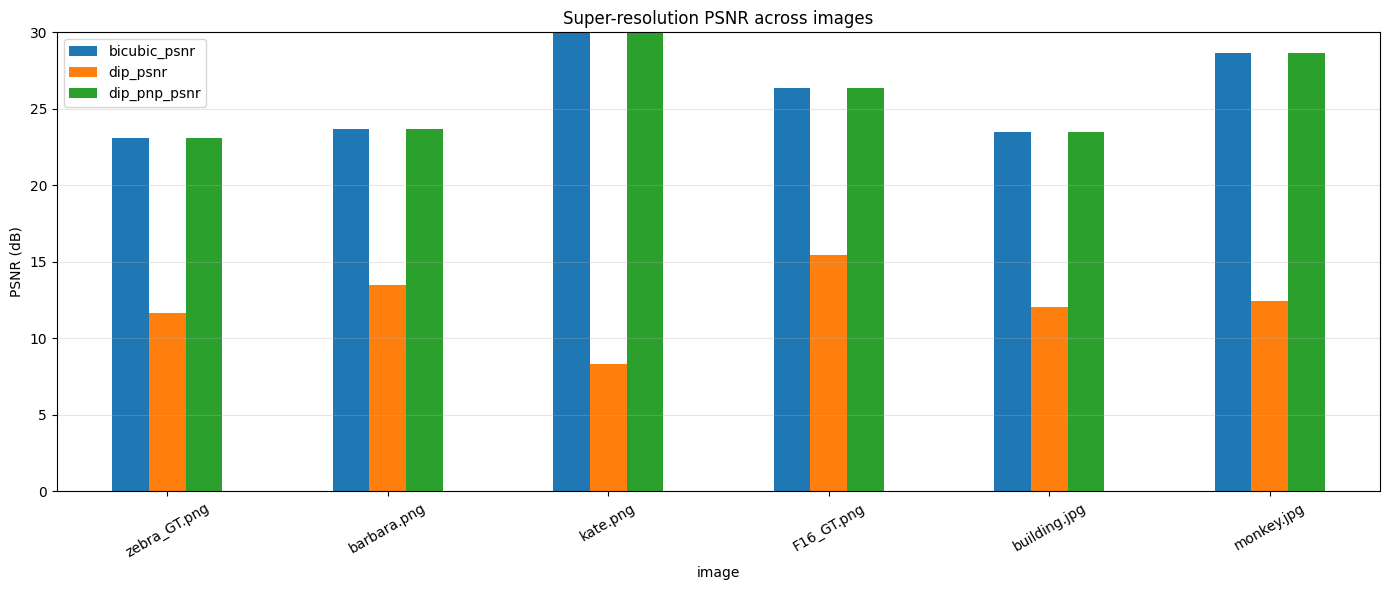

In [22]:
plot_df = results_df.set_index("image")[
    ["bicubic_psnr", "dip_psnr", "dip_pnp_psnr"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(14, 6),
    ylim=(0, 30),
    rot=30,
    title="Super-resolution PSNR across images",
)

ax.set_ylabel("PSNR (dB)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

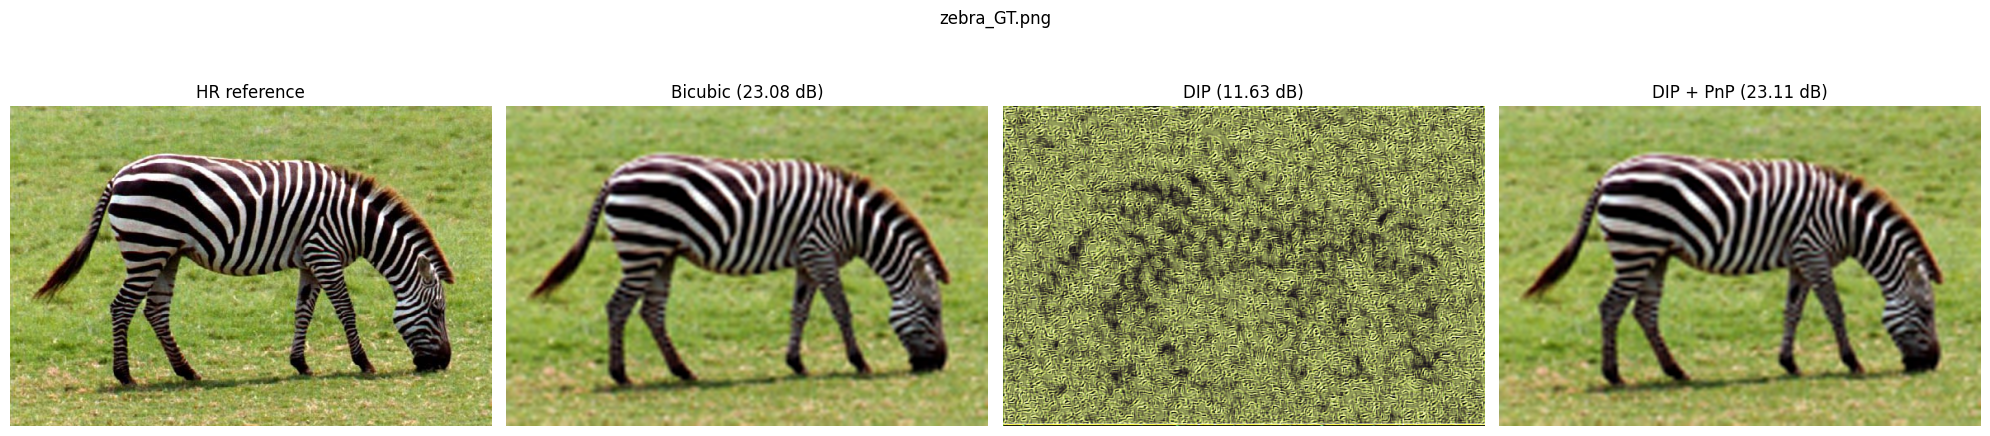

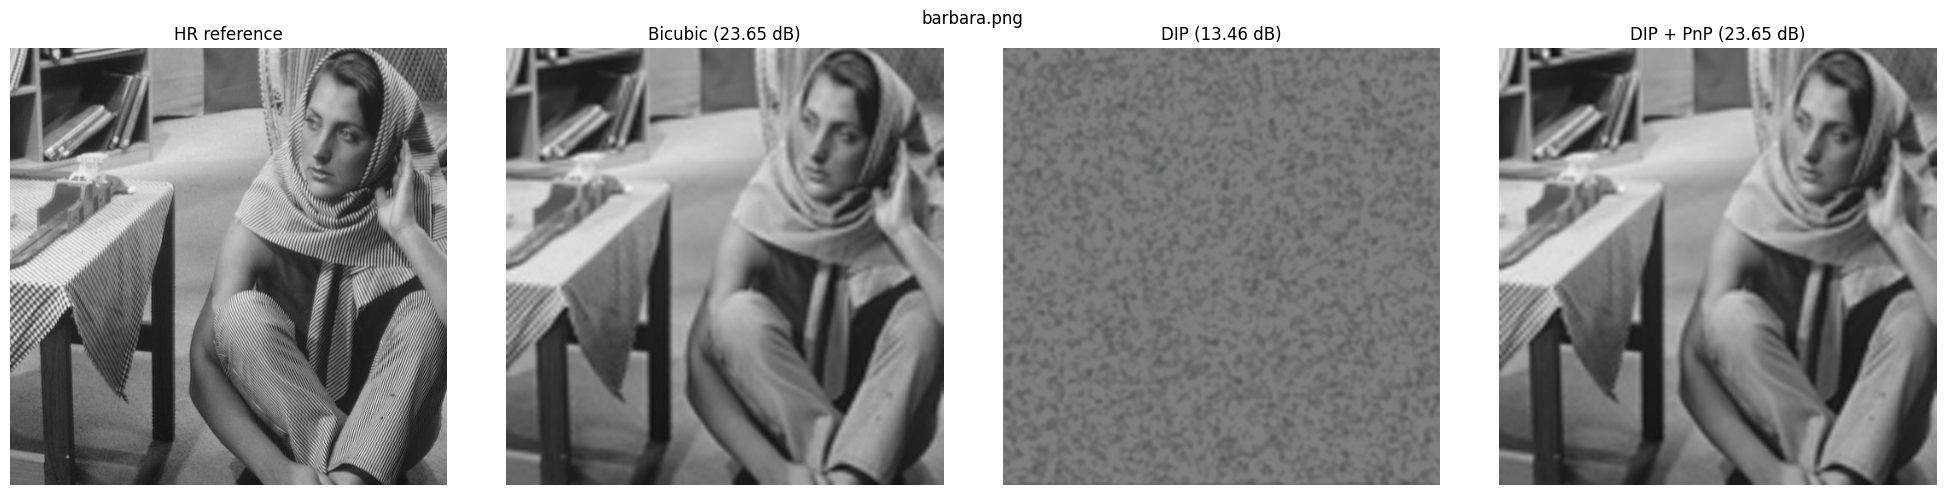

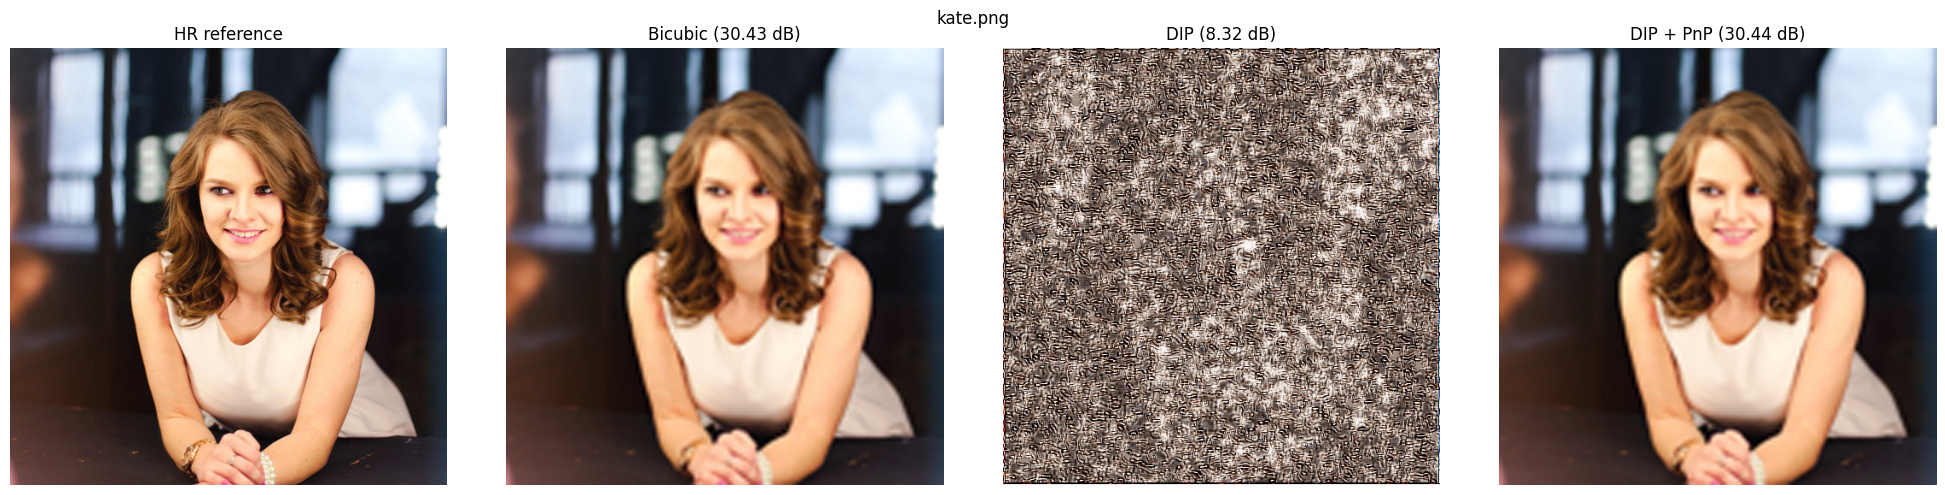

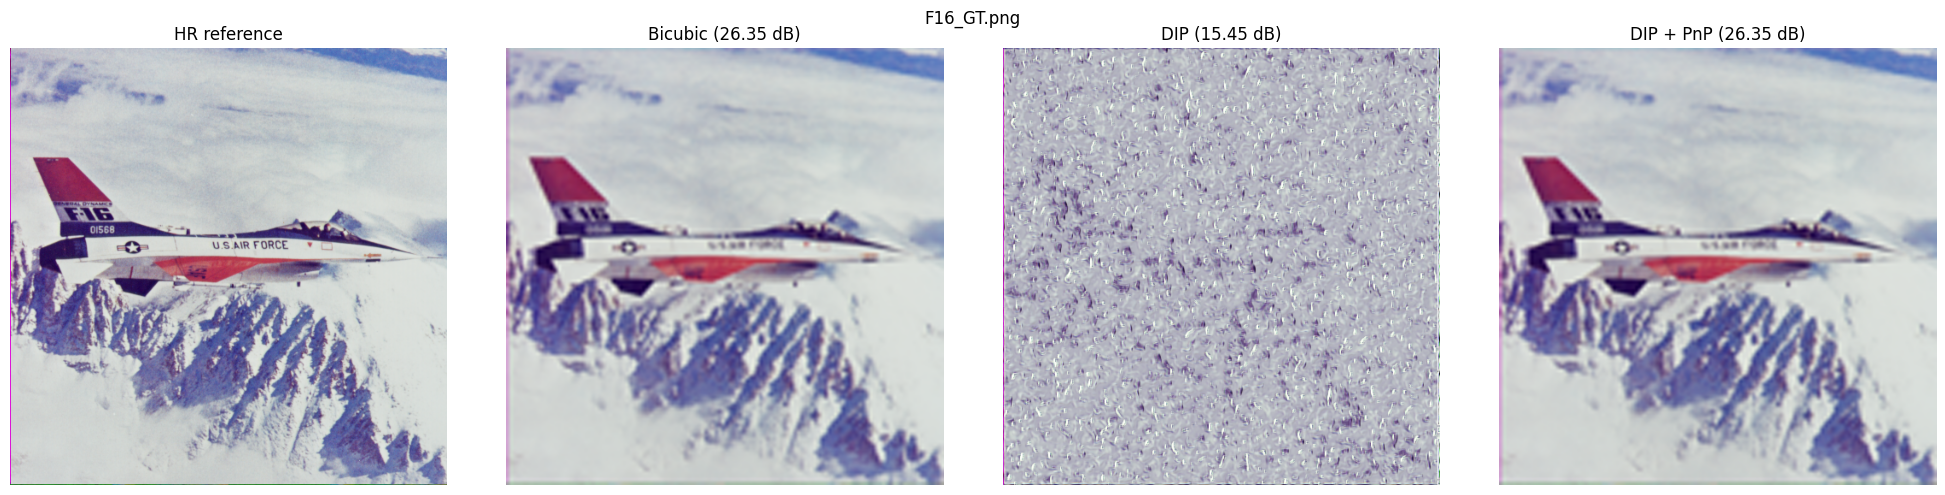

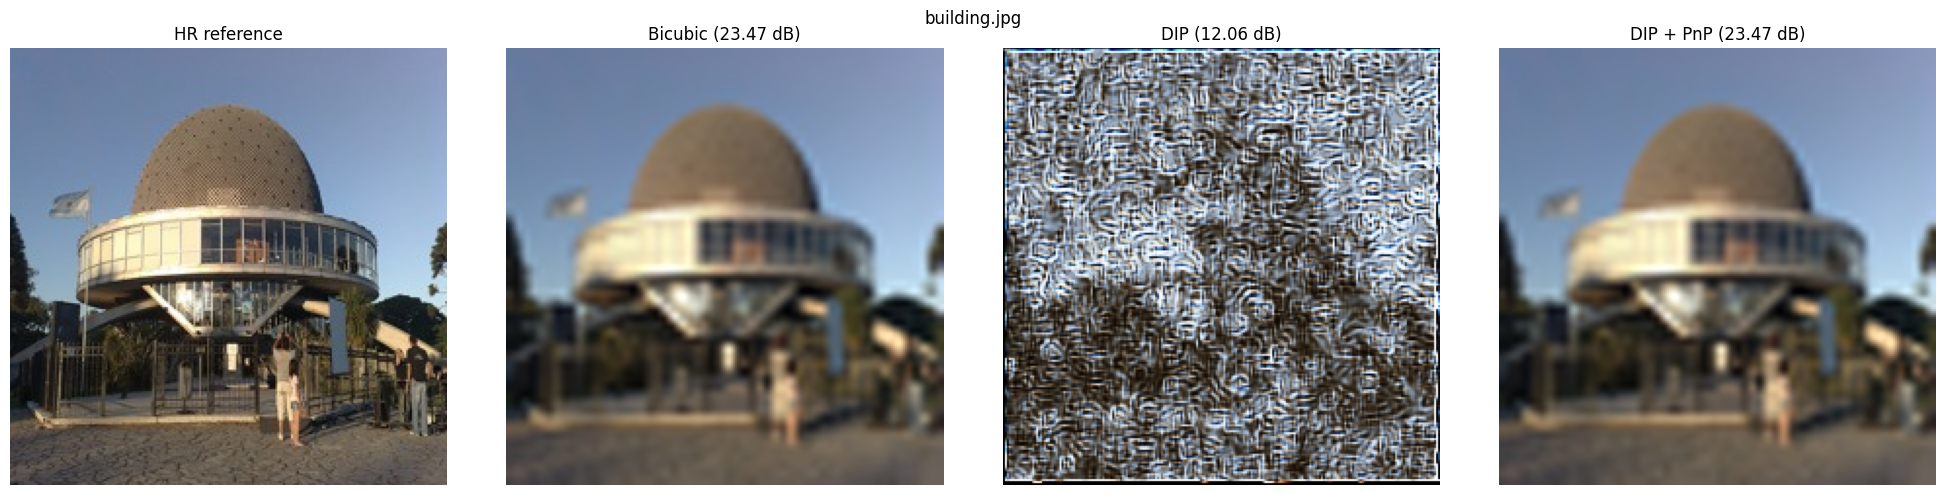

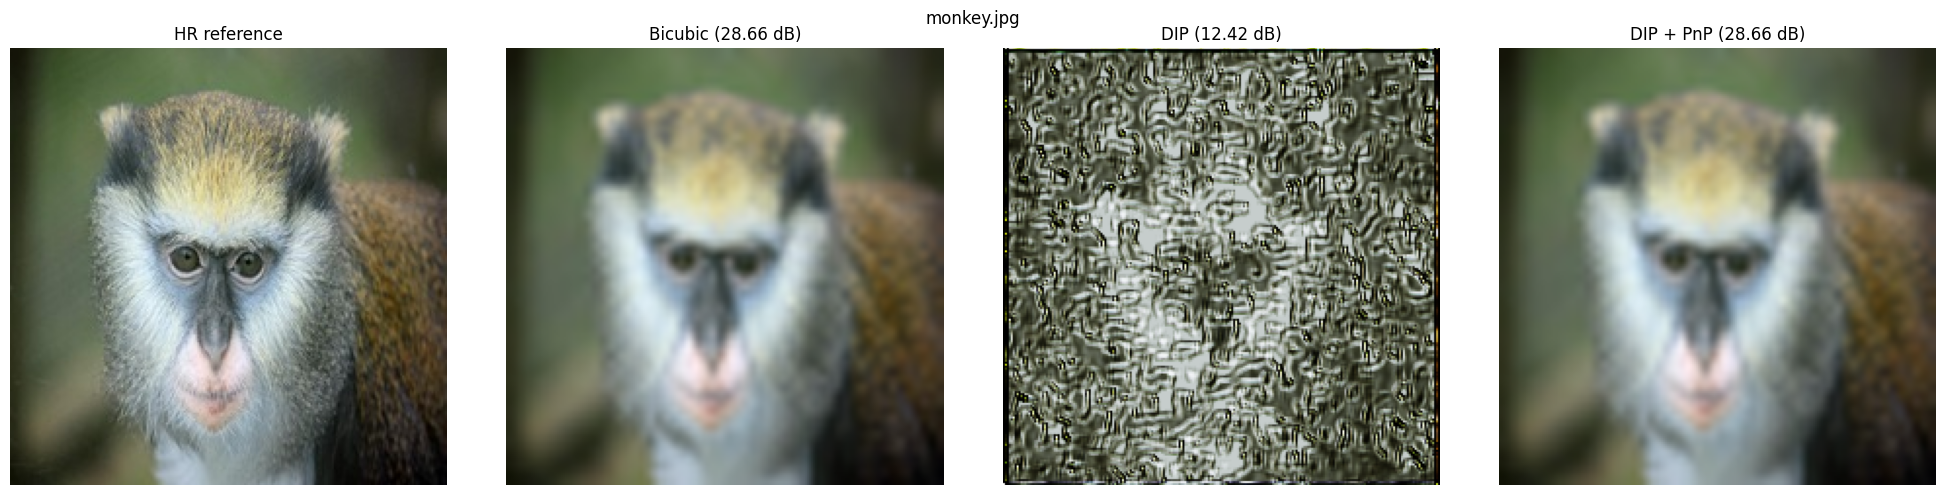

In [23]:
for result in results:
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    images = [
        result["hr"],
        result["bicubic"],
        result["dip"],
        result["dip_pnp"],
    ]

    titles = [
        "HR reference",
        f"Bicubic ({psnr(images[1], images[0]):.2f} dB)",
        f"DIP ({psnr(images[2], images[0]):.2f} dB)",
        f"DIP + PnP ({psnr(images[3], images[0]):.2f} dB)",
    ]

    for axis, image_tensor, title in zip(axes, images, titles):
        axis.imshow(tensor_to_image(image_tensor))
        axis.set_title(title)
        axis.axis("off")

    fig.suptitle(result["image"])
    plt.tight_layout()
    plt.show()